# 01 · Análisis exploratorio (EDA) — FireWatch Boyacá

**Dueño:** B · **Tarea:** B8 · **Entrada:** `data/silver/` (`content_sha256` a41f8fb8, ADR-0005), con reconciliación contra `data/gold/` tras el data freeze · **Requisito:** R6 (≥6 visualizaciones con Matplotlib/Seaborn; meta: 7)

Regla: cada gráfico va seguido de una celda **Hallazgo** de 2–3 frases. Esas frases se usan en el IEEE y en la sustentación.

## 0. Carga y verificación
Conteos y reconciliación con silver.

In [1]:
# === Celda 0 · Configuración, carga y verificación ===
from pathlib import Path
import yaml
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

# --- Rutas y parámetros: todo sale de settings.yaml ---
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CFG = yaml.safe_load((ROOT / "config/settings.yaml").read_text(encoding="utf-8"))
SILVER = ROOT / CFG["rutas"]["silver"]
GOLD = ROOT / CFG["rutas"]["gold"]
DPTO = CFG["territorio"]["cod_dpto_foco"]
INI = pd.Timestamp(CFG["ventana"]["fecha_inicio"])
FIN = pd.Timestamp(CFG["ventana"]["fecha_fin"])
FIG_DIR = ROOT / "docs/figures/eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# --- Estilo único para todas las figuras ---
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight"})

# --- Paleta del proyecto: el color depende de la TAREA que cumple ---
CMAP_MAGNITUD = "YlOrRd"            # secuencial: cantidad de fuego (heatmap, mapa)
CMAP_POLARIDAD = "coolwarm"         # divergente con centro neutro: correlaciones (−1 … +1)
C_FUEGO = "#BD0026"                 # acento de una sola serie = extremo oscuro de YlOrRd
C_NEUTRO = "0.25"                   # líneas de referencia y acumulados
C_DIA, C_NOCHE = "#E6550D", "#5E3C99"
C_NINO, C_NINA = "#B2182B", "#2166AC"   # convención NOAA (validado para daltonismo)

def guardar(fig, nombre):
    fig.savefig(FIG_DIR / f"{nombre}.png")
    print(f"→ docs/figures/eda/{nombre}.png")

# --- Detecciones de Boyacá (vegetación = sin fuentes estáticas) ---
COLS = ["id_det", "fecha", "anio", "mes", "daynight", "confianza", "frp",
        "satelite", "proceso", "fuente_estatica", "cod_mpio", "lat", "lon"]
det = pd.read_parquet(SILVER / "detecciones", columns=COLS,
                      filters=[("cod_dpto", "==", DPTO)])
det["anio"] = det["anio"].astype(int)
det["fecha"] = pd.to_datetime(det["fecha"])
n_estaticas = int(det["fuente_estatica"].sum())
det = det[~det["fuente_estatica"] & det["fecha"].between(INI, FIN)].drop(columns="fuente_estatica")
det["fecha_mes"] = det["fecha"].dt.to_period("M").dt.to_timestamp()

# --- Contexto nacional (gráfica 8): solo conteos por departamento ---
nac = pd.read_parquet(SILVER / "detecciones", columns=["cod_dpto", "fuente_estatica", "fecha"])
nac = nac[~nac["fuente_estatica"] & nac["cod_dpto"].notna()]
dim_dpto = pd.read_parquet(SILVER / "dim_departamento")
det_dpto = (nac.groupby("cod_dpto").size().rename("n_det").reset_index()
               .merge(dim_dpto, on="cod_dpto", how="left")
               .sort_values("n_det", ascending=False))
del nac

# --- Dimensiones y geometría de Boyacá ---
dim_mpio = pd.read_parquet(SILVER / "dim_municipio")
geo = gpd.read_parquet(SILVER / "geo_municipios")
geo = geo[geo["cod_dpto"] == DPTO].merge(dim_mpio, on="cod_mpio")

# --- Grilla municipio × mes CON CEROS ---
meses = pd.date_range(INI, FIN, freq="MS")
grilla = pd.MultiIndex.from_product([dim_mpio["cod_mpio"], meses],
                                    names=["cod_mpio", "fecha_mes"]).to_frame(index=False)
conteo = (det.groupby(["cod_mpio", "fecha_mes"])
             .agg(n_det=("id_det", "size"), frp_total=("frp", "sum")).reset_index())
mm = grilla.merge(conteo, on=["cod_mpio", "fecha_mes"], how="left")
mm = mm.fillna({"n_det": 0, "frp_total": 0.0}).astype({"n_det": int})

# --- Clima: horario → diario (mismas definiciones que build_daily) → mensual ---
clima = pd.read_parquet(SILVER / "clima_horario",
                        columns=["cod_mpio", "fecha", "temp", "rh", "precip", "wind"])
diario = (clima.groupby(["cod_mpio", "fecha"])
               .agg(tmax=("temp", "max"), rh_min=("rh", "min"),
                    precip=("precip", "sum"), wind_max=("wind", "max")).reset_index())
del clima
diario["fecha_mes"] = pd.to_datetime(diario["fecha"]).dt.to_period("M").dt.to_timestamp()
clima_mes = (diario.groupby(["cod_mpio", "fecha_mes"])
                   .agg(precip_mes=("precip", "sum"), tmax_media=("tmax", "mean"),
                        rh_min_media=("rh_min", "mean"), wind_max_media=("wind_max", "mean"))
                   .reset_index())
mm = (mm.merge(clima_mes, on=["cod_mpio", "fecha_mes"], how="left")
        .merge(dim_mpio[["cod_mpio", "nombre", "provincia", "area_km2"]], on="cod_mpio"))
mm["det_100km2"] = mm["n_det"] / mm["area_km2"] * 100

# --- Verificación ---
print(f"Detecciones Boyacá (vegetación): {len(det):,}  | fuentes estáticas excluidas: {n_estaticas:,}")
print(f"Municipios con detecciones: {det['cod_mpio'].nunique()}/{len(dim_mpio)}")
print(f"Grilla: {len(mm):,} filas (esperado {len(dim_mpio) * len(meses):,})")
print(f"Municipio-mes sin detecciones: {(mm['n_det'] == 0).mean():.1%}")
print(f"Clima faltante en la grilla: {mm['precip_mes'].isna().sum()}")
print(f"Provincias cargadas: {dim_mpio['provincia'].notna().sum()}/{len(dim_mpio)}")

assert det["id_det"].is_unique
assert det["cod_mpio"].isin(dim_mpio["cod_mpio"]).all()
assert len(mm) == len(dim_mpio) * len(meses)
assert mm["n_det"].sum() == len(det)

fact = GOLD / "fact_municipio_mes"
if fact.exists():
    g = pd.read_parquet(fact, columns=["cod_mpio", "fecha_mes", "n_det"])
    g["fecha_mes"] = pd.to_datetime(g["fecha_mes"])
    cmp = mm.merge(g, on=["cod_mpio", "fecha_mes"], suffixes=("_silver", "_gold"))
    print(f"Reconciliación con gold: {(cmp['n_det_silver'] != cmp['n_det_gold']).sum()} "
          f"municipio-mes distintos de {len(cmp)}")
else:
    print("Gold aún no existe → reconciliación pendiente (volver a correr tras el freeze).")

Detecciones Boyacá (vegetación): 3,908  | fuentes estáticas excluidas: 1,098
Municipios con detecciones: 107/123
Grilla: 7,134 filas (esperado 7,134)
Municipio-mes sin detecciones: 88.7%
Clima faltante en la grilla: 0
Provincias cargadas: 0/123
Gold aún no existe → reconciliación pendiente (volver a correr tras el freeze).


## 1. Serie mensual y fases ENSO

→ docs/figures/eda/eda01_monthly_series_enso.png


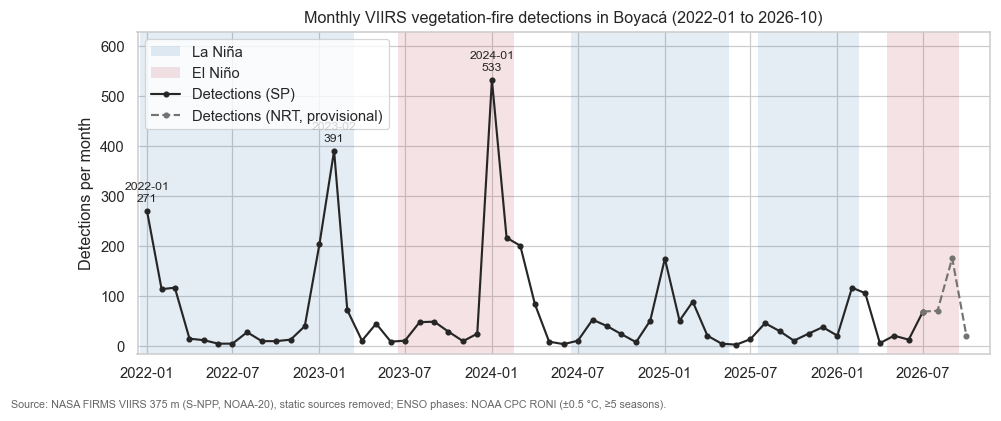

Detecciones por año:
 anio
2022     640
2023     904
2024    1235
2025     508
2026     621 

Top 5 meses:
  fecha_mes  n_det
2024-01-01    533
2023-02-01    391
2022-01-01    271
2024-02-01    217
2023-01-01    204 

                    count  mean  median
fase                                   
La Niña                33  64.3    30.0
Neutral / sin dato     12  42.8    12.5
El Niño                13  97.8    48.0


In [2]:
# === Gráfica 1 · Serie mensual de detecciones con fases ENSO (RONI, NOAA CPC) ===
roni = pd.read_csv(ROOT / "config/enso_roni.csv", comment="#")
roni["fecha_mes"] = pd.to_datetime(dict(year=roni["anio"], month=roni["mes_central"], day=1))

def fases_enso(valores, umbral=0.5, minimo=5):
    """+1 El Niño, -1 La Niña, 0 neutral: umbral ±0.5 °C sostenido ≥ 5 temporadas."""
    s = pd.Series(np.where(valores >= umbral, 1, np.where(valores <= -umbral, -1, 0)))
    racha = (s != s.shift()).cumsum()
    largo = s.groupby(racha).transform("size")
    return np.where(largo >= minimo, s, 0)

roni["fase"] = fases_enso(roni["roni"].to_numpy())
serie = mm.groupby("fecha_mes", as_index=False)["n_det"].sum()

fig, ax = plt.subplots(figsize=(10, 3.8))
r = roni[roni["fecha_mes"].between(INI, FIN)].reset_index(drop=True)
ya = set()
for _, b in r.groupby((r["fase"] != r["fase"].shift()).cumsum()):
    f = b["fase"].iloc[0]
    if f == 0:
        continue
    color, etiqueta = (C_NINA, "La Niña") if f < 0 else (C_NINO, "El Niño")
    ax.axvspan(b["fecha_mes"].iloc[0] - pd.Timedelta(days=15),
               b["fecha_mes"].iloc[-1] + pd.Timedelta(days=15),
               color=color, alpha=0.12, lw=0, label=None if etiqueta in ya else etiqueta)
    ya.add(etiqueta)

nrt_ini = det.loc[det["proceso"] == "NRT", "fecha_mes"].min()
sp = serie[serie["fecha_mes"] < nrt_ini]
nrt = serie[serie["fecha_mes"] >= nrt_ini - pd.DateOffset(months=1)]   # une con el último mes SP
ax.plot(sp["fecha_mes"], sp["n_det"], marker="o", ms=3, lw=1.4, color="0.15", label="Detections (SP)")
ax.plot(nrt["fecha_mes"], nrt["n_det"], marker="o", ms=3, lw=1.4, ls="--", color="0.45",
        label="Detections (NRT, provisional)")
for _, t in serie.nlargest(3, "n_det").iterrows():
    ax.annotate(f"{t.fecha_mes:%Y-%m}\n{int(t.n_det)}", (t.fecha_mes, t.n_det),
                textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8)
ax.set(title="Monthly VIIRS vegetation-fire detections in Boyacá (2022-01 to 2026-10)",
       ylabel="Detections per month", xlabel="")
ax.set_xlim(INI - pd.Timedelta(days=20), FIN + pd.Timedelta(days=20))
ax.set_ylim(bottom=-15, top=serie["n_det"].max() * 1.18)
ax.legend(loc="upper left", frameon=True)
fig.text(0.01, -0.02, "Source: NASA FIRMS VIIRS 375 m (S-NPP, NOAA-20), static sources removed; "
         "ENSO phases: NOAA CPC RONI (±0.5 °C, ≥5 seasons).", fontsize=7, color="0.4")
guardar(fig, "eda01_monthly_series_enso")
plt.show()

# --- Números para el Hallazgo ---
print("Detecciones por año:\n", det.groupby("anio").size().to_string(), "\n")
print("Top 5 meses:\n", serie.nlargest(5, "n_det").to_string(index=False), "\n")
pf = serie.merge(roni[["fecha_mes", "fase"]], on="fecha_mes", how="left").fillna({"fase": 0})
print(pf.groupby("fase")["n_det"].agg(["count", "mean", "median"])
        .rename(index={-1: "La Niña", 0: "Neutral / sin dato", 1: "El Niño"}).round(1))

**Hallazgo 1.** Las detecciones siguen un ciclo estacional fuerte: el pico ocurre cada año en enero–febrero (temporada seca) y hay un segundo pico, menor, en agosto–septiembre. El máximo de la serie (533 detecciones, enero de 2024) coincide con El Niño 2023–24; enero–marzo de 2024 concentra el 77 % de las detecciones de ese año. La Niña no suprime la temporada (391 en febrero de 2023): ENSO modula la intensidad del pico, no lo origina. Los meses de El Niño promedian 97,8 detecciones (mediana 48) frente a 64,3 (mediana 30) en La Niña, pero esa comparación mezcla meses de distinta estación (ver Hallazgo 2). Agosto–octubre de 2026 son NRT y se tratan como provisionales.

## 2. Estacionalidad mes × año

→ docs/figures/eda/eda02_seasonality_heatmap.png


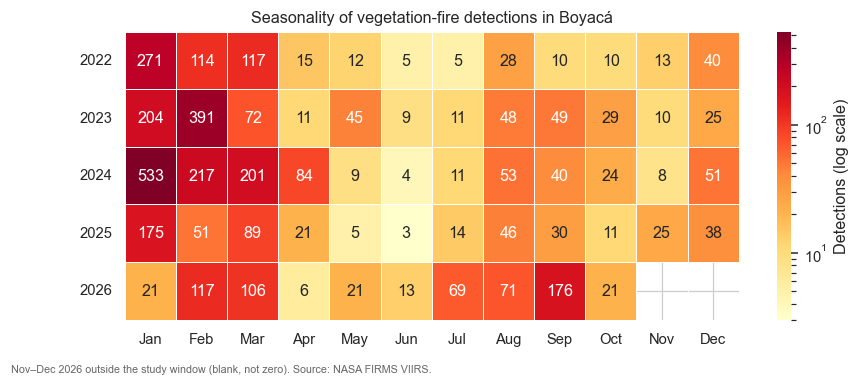

Porcentaje del año en ene–mar:
 anio
2022    78.4
2023    73.8
2024    77.0
2025    62.0
2026    39.3 

Porcentaje de cada mes sobre el total 2022–2026:
 mes
Jan    30.8
Feb    22.8
Mar    15.0
Apr     3.5
May     2.4
Jun     0.9
Jul     2.8
Aug     6.3
Sep     7.8
Oct     2.4
Nov     1.4
Dec     3.9


In [3]:
# === Gráfica 2 · Estacionalidad: heatmap mes × año ===
from matplotlib.colors import LogNorm

tabla = (mm.assign(anio=mm["fecha_mes"].dt.year, mes=mm["fecha_mes"].dt.month)
           .pivot_table(index="anio", columns="mes", values="n_det", aggfunc="sum"))
MESES_EN = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(9, 3.4))
sns.heatmap(tabla, annot=True, fmt=".0f", cmap=CMAP_MAGNITUD, linewidths=0.5, linecolor="white",
            norm=LogNorm(vmin=max(1, tabla.min().min()), vmax=tabla.max().max()),
            mask=tabla.isna(), cbar_kws={"label": "Detections (log scale)"}, ax=ax)
ax.set_xticklabels(MESES_EN, rotation=0)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set(title="Seasonality of vegetation-fire detections in Boyacá", xlabel="", ylabel="")
fig.text(0.01, -0.03, "Nov–Dec 2026 outside the study window (blank, not zero). "
         "Source: NASA FIRMS VIIRS.", fontsize=7, color="0.4")
guardar(fig, "eda02_seasonality_heatmap")
plt.show()

# --- Números para el Hallazgo ---
anual = tabla.sum(axis=1)
temporada = tabla[[1, 2, 3]].sum(axis=1)
print("Porcentaje del año en ene–mar:\n", (temporada / anual * 100).round(1).to_string(), "\n")
print("Porcentaje de cada mes sobre el total 2022–2026:\n",
      (tabla.sum() / tabla.sum().sum() * 100).round(1).rename(dict(enumerate(MESES_EN, 1))).to_string())

### Diagnóstico de calidad 1 · ¿Enero de 2026 es real o un hueco de datos?
Hipótesis: (A) faltan días o un satélite, (B) cambio SP→NRT, (C) enero lluvioso. Resultado: se descartan A y B (31/31 días por satélite, 100 % SP); se confirma C (207 mm frente a 21 mm en 2024).

In [4]:
# === Diagnóstico: ¿enero de 2026 es real o un hueco de datos? ===
d = pd.read_parquet(SILVER / "detecciones", columns=["fecha", "satelite", "proceso", "fuente_estatica"])
d = d[~d["fuente_estatica"]].copy()
d["fecha"] = pd.to_datetime(d["fecha"])
d["periodo"] = d["fecha"].dt.to_period("M")

# Hipótesis A: ¿cae también Colombia? ¿falta un satélite?
ene = d[d["periodo"].dt.month == 1]
print("Colombia, enero de cada año, por satélite:\n",
      ene.groupby([ene["periodo"].dt.year, "satelite"]).size().unstack().to_string(), "\n")
print("Días con datos en enero de 2026, por satélite (máx. 31):\n",
      d[d["periodo"] == pd.Period("2026-01", "M")].groupby("satelite")["fecha"].nunique().to_string(), "\n")

# Hipótesis B: ¿dónde pasa de SP a NRT?
ult = d[d["periodo"] >= pd.Period("2025-10", "M")]
print("Colombia, oct-2025 → oct-2026, por satélite y proceso:\n",
      ult.groupby(["periodo", "satelite", "proceso"]).size().unstack(["satelite", "proceso"])
         .fillna(0).astype(int).to_string(), "\n")

# Hipótesis C: ¿enero de 2026 fue lluvioso en Boyacá?
pe = mm[mm["fecha_mes"].dt.month == 1]
print("Boyacá, precipitación media de enero por municipio (mm):\n",
      pe.groupby(pe["fecha_mes"].dt.year)["precip_mes"].mean().round(1).to_string())
del d, ene, ult

Colombia, enero de cada año, por satélite:
 satelite      N    N20
periodo               
2022      38216  37844
2023      11560  11304
2024      22394  22626
2025      12830  13707
2026       6170   5447 

Días con datos en enero de 2026, por satélite (máx. 31):
 satelite
N      31
N20    31 

Colombia, oct-2025 → oct-2026, por satélite y proceso:
 satelite      N    N20     N   N20
proceso      SP     SP   NRT   NRT
periodo                           
2025-10    2055   2029     0     0
2025-11    2329   2469     0     0
2025-12    7751   7672     0     0
2026-01    6170   5447     0     0
2026-02   15640  14960     0     0
2026-03   20179  19700     0     0
2026-04    3427   3703     0     0
2026-05    2077   1880     0     0
2026-06    1688   2168     0     0
2026-07    2791   3514     0     0
2026-08       0      0  5459  5305
2026-09       0      0  4494  4363
2026-10       0      0  2494  2591 

Boyacá, precipitación media de enero por municipio (mm):
 fecha_mes
2022     59.4
2023

**Hallazgo 2.** El régimen es bimodal: enero–marzo concentra el 68,6 % de las detecciones y agosto–septiembre el 14,1 %; los mínimos (abril–mayo y octubre–noviembre, junio con 0,9 %) coinciden con las temporadas de lluvia andinas, lo que da coherencia física a los datos. Comparando el mismo mes, El Niño multiplica la actividad (enero de 2024: 533, frente a 175–271 en 2022, 2023 y 2025). Enero de 2026 (21 detecciones) no es un error de datos —cobertura completa de ambos satélites y procesamiento SP—, sino un enero excepcionalmente lluvioso (207 mm frente a 21 mm en 2024). Enero de 2022, con La Niña pero seco (59 mm), registró 271: la precipitación observada ordena los eneros (ρ de Spearman = −0,9; n = 5; enero de 2025: 175) mejor que la fase ENSO.

## 3. Distribución del FRP

→ docs/figures/eda/eda03_frp_distribution.png


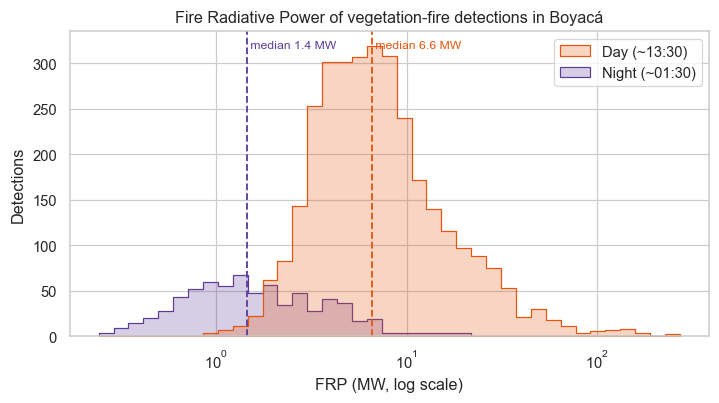

count    3908.00
mean        9.41
std        15.09
min         0.24
50%         5.55
90%        19.39
99%        64.70
max       274.09 

El 10 % de detecciones más intensas concentra el 42.7% del FRP total
Media / mediana = 1.7  (≈1 si fuera simétrica)

          count  median   mean
daynight                      
D          3211    6.61  10.95
N           697    1.45   2.30


In [5]:
# === Gráfica 3 · Distribución del FRP (escala log, día vs noche) ===
frp = det["frp"]
bins = np.logspace(np.log10(frp.min()), np.log10(frp.max()), 40)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
sns.histplot(data=det, x="frp", hue="daynight", hue_order=["D", "N"], bins=bins,
             element="step", palette={"D": C_DIA, "N": C_NOCHE}, ax=ax)
ax.set_xscale("log")
for dn, color in [("D", C_DIA), ("N", C_NOCHE)]:
    v = det.loc[det["daynight"] == dn, "frp"].median()
    ax.axvline(v, color=color, ls="--", lw=1.2)
    ax.text(v, ax.get_ylim()[1] * 0.97, f" median {v:.1f} MW", color=color, fontsize=8, va="top")
leg = ax.get_legend()
leg.set_title("")
for t, nombre in zip(leg.texts, ["Day (~13:30)", "Night (~01:30)"]):
    t.set_text(nombre)
ax.set(title="Fire Radiative Power of vegetation-fire detections in Boyacá",
       xlabel="FRP (MW, log scale)", ylabel="Detections")
guardar(fig, "eda03_frp_distribution")
plt.show()

# --- Números para el Hallazgo ---
print(frp.describe(percentiles=[0.5, 0.9, 0.99]).round(2).to_string(), "\n")
s = frp.sort_values(ascending=False)
top10 = s.iloc[: int(len(s) * 0.10)].sum() / s.sum()
print(f"El 10 % de detecciones más intensas concentra el {top10:.1%} del FRP total")
print(f"Media / mediana = {frp.mean() / frp.median():.1f}  (≈1 si fuera simétrica)\n")
print(det.groupby("daynight")["frp"].agg(["count", "median", "mean"]).round(2))

**Hallazgo 3.** El FRP tiene cola pesada: la mediana es 5,6 MW, pero el 10 % más intenso concentra el 42,7 % de la energía radiada (máximo 274 MW). La distribución es bimodal porque mezcla dos poblaciones: las detecciones diurnas (82 %, mediana 6,6 MW) captan el pico de actividad de la tarde, y las nocturnas (18 %, mediana 1,4 MW) fuegos residuales que el sensor detecta mejor con fondo frío. Antes de ampliar la máscara de fuentes estáticas (ADR-0005), las nocturnas eran el 25 %: 382 de las 386 detecciones reclasificadas como industriales eran nocturnas, una validación independiente de la regla. Consecuencia: los agregados de FRP deben usar la mediana o separar día y noche.

## 4. Mapa de densidad por municipio

→ docs/figures/eda/eda04_density_map.png


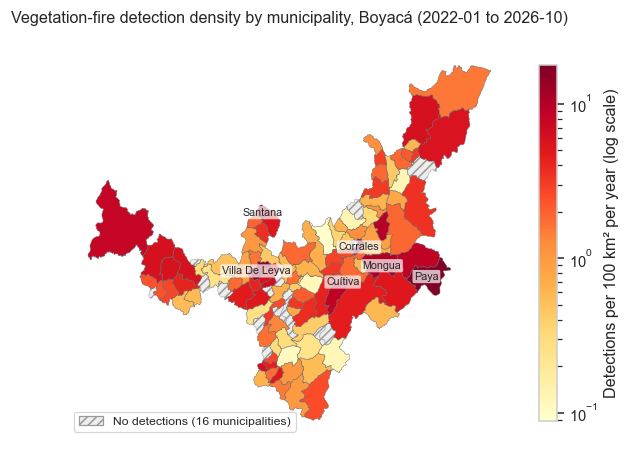

Top 10 por DENSIDAD:
         nombre  n_det  area_km2  dens_anual
          PAYA    382    442.76       17.85
      CORRALES     46     60.73       15.67
VILLA DE LEYVA     86    126.38       14.08
       SANTANA     41     67.85       12.50
        MONGUA    183    360.04       10.52
       CUÍTIVA     21     44.04        9.87
         SOCHA     71    149.88        9.80
         PISBA    197    463.88        8.79
          TOTA     82    195.66        8.67
 PUERTO BOYACÁ    573   1512.08        7.84 

Top 10 por CONTEO:
              nombre  n_det  area_km2  dens_anual
      PUERTO BOYACÁ    573   1512.08        7.84
               PAYA    382    442.76       17.85
GÜICÁN DE LA SIERRA    261    949.90        5.68
          AQUITANIA    209    940.35        4.60
              PISBA    197    463.88        8.79
            CHISCAS    188    657.28        5.92
             MONGUA    183    360.04       10.52
     LABRANZAGRANDE    144    579.99        5.14
            OTANCHE    136    4

In [6]:
# === Gráfica 4 · Mapa de densidad de detecciones por municipio ===
from matplotlib.patches import Patch

anios = len(meses) / 12
dens = mm.groupby("cod_mpio", as_index=False)["n_det"].sum()
g4 = geo.merge(dens, on="cod_mpio").to_crs("EPSG:9377")          # MAGNA-SIRGAS Origen Nacional
g4["dens_anual"] = g4["n_det"] / g4["area_km2"] * 100 / anios    # det / 100 km² / año

cero, pos = g4[g4["n_det"] == 0], g4[g4["n_det"] > 0]
fig, ax = plt.subplots(figsize=(6.5, 7))
cero.plot(ax=ax, color="0.93", edgecolor="0.6", linewidth=0.3, hatch="////")
pos.plot(ax=ax, column="dens_anual", cmap=CMAP_MAGNITUD, edgecolor="0.4", linewidth=0.3,
         norm=LogNorm(vmin=pos["dens_anual"].min(), vmax=pos["dens_anual"].max()), legend=True,
         legend_kwds={"label": "Detections per 100 km² per year (log scale)", "shrink": 0.6})
for _, r in g4.nlargest(6, "dens_anual").iterrows():
    p = r.geometry.representative_point()
    ax.annotate(r["nombre"].title(), (p.x, p.y), fontsize=7, ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.7))
ax.legend(handles=[Patch(facecolor="0.93", edgecolor="0.6", hatch="////",
                         label=f"No detections ({len(cero)} municipalities)")],
          loc="lower left", fontsize=8, frameon=True)
ax.set_axis_off()
ax.set_title("Vegetation-fire detection density by municipality, Boyacá (2022-01 to 2026-10)")
guardar(fig, "eda04_density_map")
plt.show()

# --- Números para el Hallazgo ---
cols = ["nombre", "n_det", "area_km2", "dens_anual"]
print("Top 10 por DENSIDAD:\n", g4.nlargest(10, "dens_anual")[cols].round(2).to_string(index=False), "\n")
print("Top 10 por CONTEO:\n", g4.nlargest(10, "n_det")[cols].round(2).to_string(index=False), "\n")
orden = g4.sort_values("n_det", ascending=False)["n_det"]
print(f"Los 10 municipios con más detecciones concentran el {orden.head(10).sum() / orden.sum():.1%}")
print(f"Densidad departamental: {g4['n_det'].sum() / g4['area_km2'].sum() * 100 / anios:.2f} det/100 km²/año")

**Hallazgo 4.** Normalizada por área, la mayor densidad se concentra en la vertiente oriental y el piedemonte llanero (Paya, 17,9 det/100 km²/año; Pisba, Labranzagrande), en municipios de páramo y alta montaña (Mongua, Tota, Güicán, Chiscas) y en los enclaves secos del altiplano (Villa de Leyva, Santana), frente a una media departamental de 3,50. 16 municipios no registraron detecciones. En la primera versión del mapa, Samacá y Ráquira encabezaban la densidad por hornos de coque y ladrilleras no enmascarados: ver el diagnóstico 2 y el ADR-0005.

### Diagnóstico de calidad 2 · ¿Hay fuentes industriales que la máscara no atrapó?
Firma industrial = misma celda en ≥ 6 meses y ≥ 3 años, predominio nocturno, sin estacionalidad y FRP bajo. Resultado: hornos en Samacá, Ráquira y Socha → máscara ampliada por persistencia (ADR-0005). La tabla siguiente es la verificación posterior al ajuste: queda un residuo de ~3 % en celdas contiguas a hornos (efecto de borde).

In [7]:
# === Diagnóstico 2: ¿hay fuentes industriales que la máscara no atrapó? ===
TAM = CFG["firms"]["mascara_estatica"]["tamano_celda_grados"]          # 0.005° ≈ 550 m
d2 = det.merge(dim_mpio[["cod_mpio", "nombre"]], on="cod_mpio")
d2["celda"] = (np.floor(d2["lat"] / TAM).astype(int).astype(str) + "_" +
               np.floor(d2["lon"] / TAM).astype(int).astype(str))
d2["periodo"] = d2["fecha"].dt.to_period("M")

por_celda = d2.groupby("celda").agg(n=("id_det", "size"), meses=("periodo", "nunique"),
                                    anios=("anio", "nunique"), lat=("lat", "mean"),
                                    lon=("lon", "mean"), nombre=("nombre", "first"))
persistentes = por_celda[(por_celda["meses"] >= 6) & (por_celda["anios"] >= 3)]
d2["persistente"] = d2["celda"].isin(persistentes.index)

res = d2.groupby("nombre").agg(
    n=("id_det", "size"), celdas=("celda", "nunique"),
    pct_persist=("persistente", "mean"),
    pct_noche=("daynight", lambda s: (s == "N").mean()),
    pct_meses_lluvia=("mes", lambda s: s.isin([4, 5, 10, 11]).mean()),
    frp_mediana=("frp", "median"))
res["det_por_celda"] = res["n"] / res["celdas"]
foco = ["SAMACÁ", "PAYA", "CORRALES", "VILLA DE LEYVA", "SOCHA", "SANTANA", "RÁQUIRA",
        "MONGUA", "CUÍTIVA", "PISBA", "PUERTO BOYACÁ", "GÜICÁN DE LA SIERRA"]
print(res.loc[[m for m in foco if m in res.index]].round(2).to_string(), "\n")
print(f"Boyacá total → persistentes: {d2['persistente'].mean():.1%} | "
      f"noche: {(d2['daynight'] == 'N').mean():.1%} | "
      f"meses de lluvia: {d2['mes'].isin([4, 5, 10, 11]).mean():.1%}\n")
print(f"Celdas persistentes (≥6 meses y ≥3 años): {len(persistentes)}, "
      f"con {persistentes['n'].sum()} detecciones\n")
print(persistentes.sort_values("meses", ascending=False).head(15).round(4).to_string())

                       n  celdas  pct_persist  pct_noche  pct_meses_lluvia  frp_mediana  det_por_celda
nombre                                                                                                
SAMACÁ                41      21         0.05       0.85              0.17         0.85           1.95
PAYA                 382     248         0.00       0.31              0.11         4.73           1.54
CORRALES              46      22         0.00       0.43              0.00         6.85           2.09
VILLA DE LEYVA        86      43         0.00       0.24              0.00         9.42           2.00
SOCHA                 71      19         0.34       0.86              0.30         0.60           3.74
SANTANA               41      26         0.00       0.00              0.20         4.55           1.58
RÁQUIRA               50      19         0.52       0.58              0.40         1.09           2.63
MONGUA               183     102         0.00       0.09              0.0

## 5. Concentración por municipio (Pareto)

→ docs/figures/eda/eda05_pareto_municipalities.png


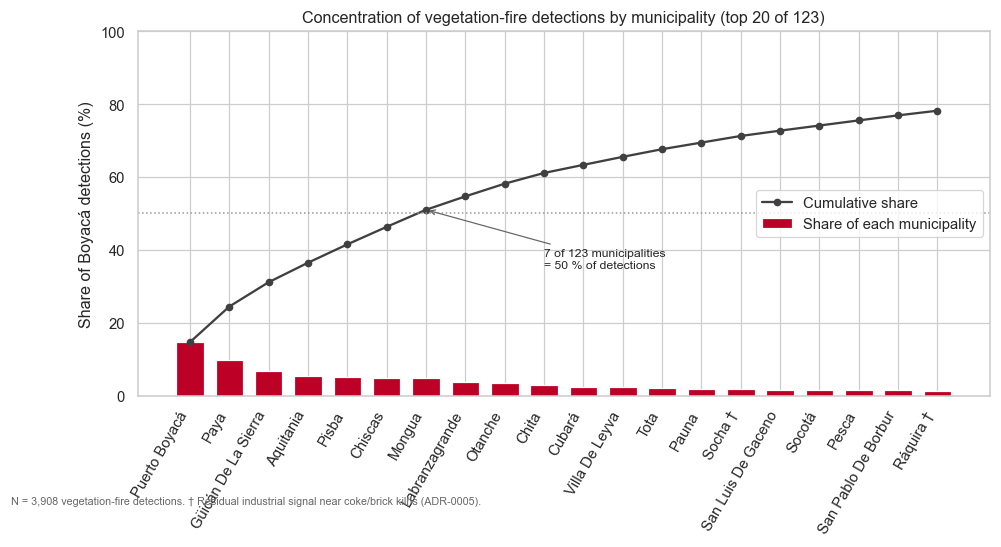

Municipios para el 50 %: 7 | para el 80 %: 22 (de 123)
Top 10: 61.1 % | sin detecciones: 16
Coeficiente de Gini entre municipios: 0.78


In [8]:
# === Gráfica 5 · Concentración por municipio (Pareto, un solo eje en %) ===
por_mpio = (mm.groupby(["cod_mpio", "nombre", "provincia"], dropna=False, as_index=False)
              .agg(n_det=("n_det", "sum"))
              .sort_values("n_det", ascending=False).reset_index(drop=True))
por_mpio["pct"] = por_mpio["n_det"] / por_mpio["n_det"].sum() * 100
por_mpio["pct_acum"] = por_mpio["pct"].cumsum()

TOP = 20
top = por_mpio.head(TOP).copy()
RESIDUO = {"SOCHA", "RÁQUIRA", "SAMACÁ"}                 # ADR-0005: residuo industrial
top["etiqueta"] = top["nombre"].str.title() + np.where(top["nombre"].isin(RESIDUO), " †", "")
if top["provincia"].notna().all():                       # cuando lleguen las provincias de A
    provs = sorted(top["provincia"].unique())
    colores = top["provincia"].map(dict(zip(provs, sns.color_palette("tab10", len(provs)))))
else:
    colores = C_FUEGO

fig, ax = plt.subplots(figsize=(10, 4.3))
ax.bar(top["etiqueta"], top["pct"], color=colores, width=0.7, label="Share of each municipality")
ax.plot(top["etiqueta"], top["pct_acum"], color=C_NEUTRO, marker="o", ms=4, lw=1.5,
        label="Cumulative share")

n50 = int((por_mpio["pct_acum"] < 50).sum()) + 1
ax.axhline(50, ls=":", color="0.6", lw=1)
ax.annotate(f"{n50} of 123 municipalities\n= 50 % of detections",
            xy=(n50 - 1, por_mpio["pct_acum"].iloc[n50 - 1]), xytext=(n50 + 2, 35),
            fontsize=8, arrowprops=dict(arrowstyle="->", color="0.4"))
ax.set_ylim(0, 100)
ax.set_ylabel("Share of Boyacá detections (%)")
plt.setp(ax.get_xticklabels(), rotation=60, ha="right")
ax.legend(loc="center right", frameon=True)
fig.text(0.01, -0.12, f"N = {int(por_mpio['n_det'].sum()):,} vegetation-fire detections. "
         "† Residual industrial signal near coke/brick kilns (ADR-0005).", fontsize=7, color="0.4")
ax.set_title(f"Concentration of vegetation-fire detections by municipality (top {TOP} of 123)")
guardar(fig, "eda05_pareto_municipalities")
plt.show()

# --- Números para el Hallazgo ---
n80 = int((por_mpio["pct_acum"] < 80).sum()) + 1
x = np.sort(por_mpio["n_det"].to_numpy())
n = len(x)
gini = ((2 * np.arange(1, n + 1) - n - 1) @ x) / (n * x.sum())
print(f"Municipios para el 50 %: {n50} | para el 80 %: {n80} (de {n})")
print(f"Top 10: {por_mpio['pct'].head(10).sum():.1f} % | sin detecciones: {(por_mpio['n_det'] == 0).sum()}")
print(f"Coeficiente de Gini entre municipios: {gini:.2f}")

**Hallazgo 5.** La actividad está muy concentrada: 7 de 123 municipios (6 %) acumulan el 50 % de las detecciones y 22 (18 %) el 80 %; el coeficiente de Gini entre municipios es 0,78. Puerto Boyacá encabeza por conteo por su extensión (1.512 km²), y por densidad lideran Paya, Corrales y Villa de Leyva (gráfica 4). Socha y Ráquira (†) conservan un residuo industrial de hornos (ADR-0005). Implicación operativa: concentrar la vigilancia en pocos municipios cubre la mitad del problema.

## 6. Correlación clima–detecciones

→ docs/figures/eda/eda06_climate_correlation.png


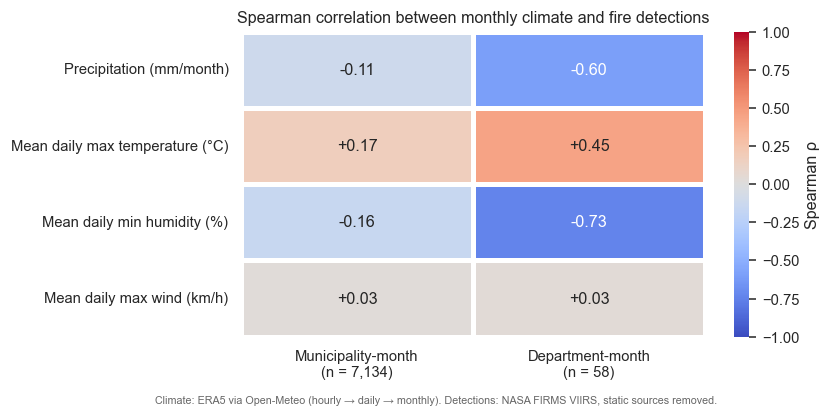

Correlación entre variables climáticas (municipio-mes, Spearman):
                 precip_mes  tmax_media  rh_min_media  wind_max_media
precip_mes            1.00        0.00          0.52           -0.39
tmax_media            0.00        1.00         -0.19           -0.17
rh_min_media          0.52       -0.19          1.00            0.03
wind_max_media       -0.39       -0.17          0.03            1.00 

Mediana del clima en municipio-meses SIN y CON detecciones:
            precip_mes  tmax_media  rh_min_media  wind_max_media
con_fuego                                                      
False           163.3        18.4          63.8             7.6
True            124.1        20.8          59.8             7.7


In [9]:
# === Gráfica 6 · Correlación clima–detecciones (Spearman) a dos escalas ===
VARS = {"precip_mes": "Precipitation (mm/month)",
        "tmax_media": "Mean daily max temperature (°C)",
        "rh_min_media": "Mean daily min humidity (%)",
        "wind_max_media": "Mean daily max wind (km/h)"}
dep = (mm.groupby("fecha_mes")
         .agg(n_det=("n_det", "sum"), **{v: (v, "mean") for v in VARS}).reset_index())
rho = pd.DataFrame({
    f"Municipality-month\n(n = {len(mm):,})": mm[list(VARS)].corrwith(mm["n_det"], method="spearman"),
    f"Department-month\n(n = {len(dep)})": dep[list(VARS)].corrwith(dep["n_det"], method="spearman"),
})
rho.index = [VARS[v] for v in rho.index]

fig, ax = plt.subplots(figsize=(6.8, 3.6))
sns.heatmap(rho, annot=True, fmt="+.2f", cmap=CMAP_POLARIDAD, vmin=-1, vmax=1, center=0,
            linewidths=2, linecolor="white", cbar_kws={"label": "Spearman ρ"}, ax=ax)
ax.set_title("Spearman correlation between monthly climate and fire detections")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
fig.text(0.01, -0.06, "Climate: ERA5 via Open-Meteo (hourly → daily → monthly). "
         "Detections: NASA FIRMS VIIRS, static sources removed.", fontsize=7, color="0.4")
guardar(fig, "eda06_climate_correlation")
plt.show()

# --- Números para el Hallazgo ---
print("Correlación entre variables climáticas (municipio-mes, Spearman):\n",
      mm[list(VARS)].corr(method="spearman").round(2).to_string(), "\n")
print("Mediana del clima en municipio-meses SIN y CON detecciones:\n",
      mm.assign(con_fuego=mm["n_det"] > 0).groupby("con_fuego")[list(VARS)].median().round(1).to_string())

**Hallazgo 6.** A escala departamental (58 meses), las detecciones se asocian con baja humedad mínima (ρ = −0,73), baja precipitación (−0,60) y alta temperatura máxima (+0,45); el viento mensual no muestra relación (+0,03). A escala municipal las correlaciones son débiles (|ρ| ≤ 0,17) por el 88,7 % de municipio-meses sin detecciones, pero las medianas muestran el mismo patrón: los meses con fuego tienen 24 % menos lluvia, +2,4 °C de temperatura máxima y 4 puntos menos de humedad. La precipitación y la humedad están correlacionadas (ρ = 0,52), por lo que en el IRAT actúan en parte como un mismo factor de sequedad. No se reportan p-valores por la autocorrelación espacial y temporal.

## 7. Correlación con rezago

→ docs/figures/eda/eda07_lagged_correlation.png


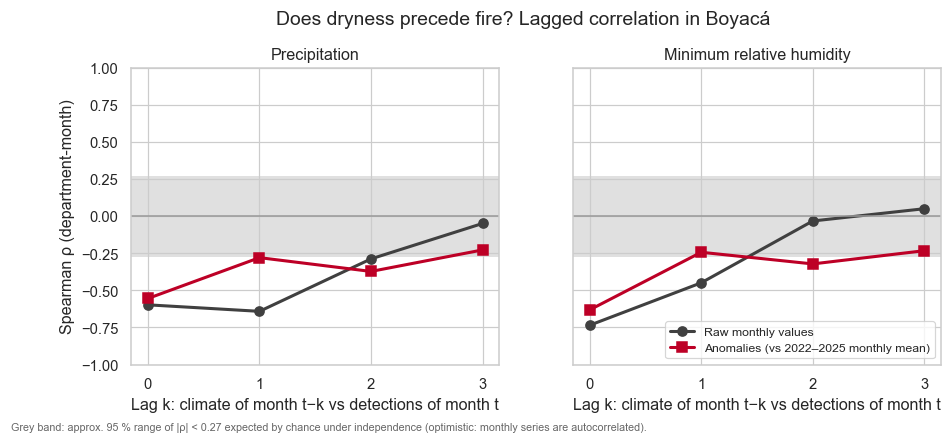

           raw                    anom             
var precip_mes rh_min_media precip_mes rh_min_media
k                                                  
0        -0.60        -0.73      -0.55        -0.63
1        -0.64        -0.45      -0.28        -0.24
2        -0.29        -0.03      -0.37        -0.32
3        -0.05         0.05      -0.23        -0.23


In [10]:
# === Gráfica 7 · ¿La sequía antecede al fuego? Correlación con rezago ===
dep = dep.sort_values("fecha_mes").reset_index(drop=True)
dep["mes"] = dep["fecha_mes"].dt.month
COLS = ["n_det", "precip_mes", "rh_min_media"]
base = dep[dep["fecha_mes"].dt.year.isin(CFG["ventana"]["anios_linea_base"])]
clim = base.groupby("mes")[COLS].mean()                       # climatología mensual 2022–2025
anom = dep[COLS] - clim.loc[dep["mes"]].to_numpy()            # anomalía = valor − media del mes

LAGS = range(0, 4)
filas = []
for var in ["precip_mes", "rh_min_media"]:
    for k in LAGS:
        filas.append({"var": var, "k": k,
                      "raw": dep["n_det"].corr(dep[var].shift(k), method="spearman"),
                      "anom": anom["n_det"].corr(anom[var].shift(k), method="spearman")})
lag = pd.DataFrame(filas)

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.5), sharey=True)
for ax, (var, titulo) in zip(axes, [("precip_mes", "Precipitation"),
                                    ("rh_min_media", "Minimum relative humidity")]):
    d = lag[lag["var"] == var]
    ax.plot(d["k"], d["raw"], marker="o", ms=6, lw=2, color=C_NEUTRO, label="Raw monthly values")
    ax.plot(d["k"], d["anom"], marker="s", ms=6, lw=2, color=C_FUEGO,
            label="Anomalies (vs 2022–2025 monthly mean)")
    ax.axhline(0, color="0.6", lw=1)
    banda = 1.96 * np.sqrt(1.06 / (len(dep) - 3))
    ax.axhspan(-banda, banda, color="0.88", lw=0, zorder=0)
    ax.set(title=titulo, xticks=list(LAGS), ylim=(-1, 1),
           xlabel="Lag k: climate of month t−k vs detections of month t")
axes[0].set_ylabel("Spearman ρ (department-month)")
axes[1].legend(loc="lower right", fontsize=8, frameon=True)
fig.suptitle("Does dryness precede fire? Lagged correlation in Boyacá", y=1.03)
fig.text(0.01, -0.06, f"Grey band: approx. 95 % range of |ρ| < {banda:.2f} expected by chance under "
         "independence (optimistic: monthly series are autocorrelated).", fontsize=7, color="0.4")
guardar(fig, "eda07_lagged_correlation")
plt.show()

# --- Números para el Hallazgo ---
print(lag.pivot(index="k", columns="var", values=["raw", "anom"]).round(2).to_string())

**Hallazgo 7.** La asociación con la sequedad no es solo estacional: con anomalías respecto a la media mensual 2022–2025, la correlación simultánea se mantiene (humedad −0,62; precipitación −0,55). En cambio, la fuerte correlación cruda de la precipitación del mes anterior (−0,64) cae a −0,27 al desestacionalizar: era un efecto del calendario (diciembre seco antecede a enero con fuego). Los rezagos de 1 a 3 meses con anomalías (−0,22 a −0,37) rozan el umbral de azar, así que el índice sirve mejor para monitorear el mes en curso que para pronosticar con un mes de anticipación.

## 8. Contexto nacional

→ docs/figures/eda/eda08_national_context.png


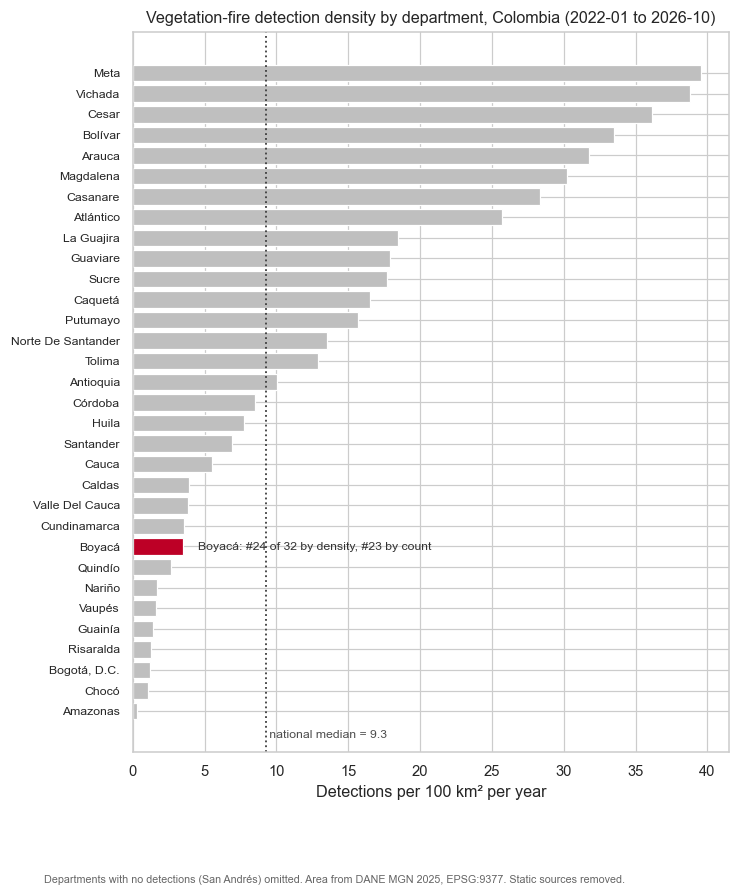

   nombre  n_det  area_km2  dens_anual  rank_conteo
     META 158013  82662.44       39.55            2
  VICHADA 186659  99635.88       38.76            1
    CESAR  39301  22498.56       36.14            7
  BOLÍVAR  43157  26680.84       33.47            6
   ARAUCA  36502  23773.09       31.77            8
MAGDALENA  33779  23110.09       30.24            9
 CASANARE  60596  44267.29       28.32            4
ATLÁNTICO   4125   3324.64       25.67           21

Boyacá: 3,908 det (0.5% del país), densidad 3.50 vs mediana nacional 9.27


In [11]:
# === Gráfica 8 · Contexto nacional: densidad por departamento ===
geo_col = gpd.read_parquet(SILVER / "geo_municipios").to_crs("EPSG:9377")
area_dpto = (geo_col.assign(area_km2=geo_col.area / 1e6)
                    .groupby("cod_dpto", as_index=False)["area_km2"].sum())
col_nombre = "nombre_dpto" if "nombre_dpto" in det_dpto.columns else "nombre"
nac8 = det_dpto.merge(area_dpto, on="cod_dpto")
nac8["dens_anual"] = nac8["n_det"] / nac8["area_km2"] * 100 / anios
nac8["rank_dens"] = nac8["dens_anual"].rank(ascending=False, method="min").astype(int)
nac8["rank_conteo"] = nac8["n_det"].rank(ascending=False, method="min").astype(int)
nac8 = nac8.sort_values("dens_anual")

fig, ax = plt.subplots(figsize=(7, 8.5))
ax.barh(nac8[col_nombre].str.title(), nac8["dens_anual"],
        color=np.where(nac8["cod_dpto"] == DPTO, C_FUEGO, "0.75"))
b = nac8[nac8["cod_dpto"] == DPTO].iloc[0]
ax.annotate(f"Boyacá: #{b.rank_dens} of {len(nac8)} by density, #{b.rank_conteo} by count",
            xy=(b.dens_anual, b[col_nombre].title()), xytext=(10, 0), textcoords="offset points",
            va="center", fontsize=8, color="0.2")
ax.set(xlabel="Detections per 100 km² per year", ylabel="",
       title="Vegetation-fire detection density by department, Colombia (2022-01 to 2026-10)")
ax.tick_params(axis="y", labelsize=8)
med = nac8["dens_anual"].median()
ax.axvline(med, ls=":", color=C_NEUTRO, lw=1.2)
ax.text(med, -0.9, f" national median = {med:.1f}", fontsize=8, color="0.3", va="top")
fig.text(0.01, -0.03, "Departments with no detections (San Andrés) omitted. Area from DANE MGN 2025, "
         "EPSG:9377. Static sources removed.", fontsize=7, color="0.4")
guardar(fig, "eda08_national_context")
plt.show()

# --- Números para el Hallazgo ---
cols8 = [col_nombre, "n_det", "area_km2", "dens_anual", "rank_conteo"]
print(nac8.sort_values("dens_anual", ascending=False)[cols8].head(8).round(2).to_string(index=False))
print(f"\nBoyacá: {int(b.n_det):,} det ({b.n_det / nac8['n_det'].sum():.1%} del país), "
      f"densidad {b.dens_anual:.2f} vs mediana nacional {nac8['dens_anual'].median():.2f}")

**Hallazgo 8.** En el contexto nacional, Boyacá concentra solo el 0,5 % de las detecciones de Colombia (puesto 23 de 32 por conteo y 24 por densidad), con 3,50 detecciones/100 km²/año frente a una mediana departamental de 9,27. El fuego del país se concentra en la Orinoquía y el Caribe (Meta y Vichada superan 38 det/100 km²/año). La relevancia de Boyacá no está en el volumen, sino en el tipo de ecosistema afectado: varios de los municipios con mayor actividad son de páramo y alta montaña (Güicán, Chiscas, Mongua, Pisba, Tota, Aquitania), cuya recuperación es lenta y de los que depende la regulación hídrica regional.

## 9. Conclusiones del EDA

1. **Estacionalidad dominante, modulada por ENSO.** El 68,6 % de las detecciones ocurre en enero–marzo y hay una segunda temporada en agosto–septiembre, en fase con el régimen de lluvias bimodal andino. El Niño 2023–24 duplicó el pico (533 detecciones en enero de 2024), pero la lluvia observada explica mejor la intensidad de cada temporada que la etiqueta ENSO (enero de 2026, lluvioso, casi sin fuego).
2. **La sequedad del mes en curso es la señal más fuerte.** A escala departamental, la humedad mínima (ρ = −0,73) y la precipitación (−0,60) se asocian con las detecciones, y la asociación se mantiene con anomalías desestacionalizadas (−0,62 y −0,55). El viento mensual no aporta (+0,03), y la señal con uno a tres meses de anticipación es débil (≤ 0,37): respalda el uso de anomalías climáticas en el IRAT como monitoreo, más que como pronóstico.
3. **Concentración espacial alta.** 7 de 123 municipios acumulan el 50 % de las detecciones (Gini = 0,78), con predominio de la vertiente oriental, el piedemonte llanero y los páramos; 16 municipios no registraron detecciones en 58 meses.
4. **Boyacá importa por el ecosistema, no por el volumen.** El departamento aporta el 0,5 % de las detecciones del país (densidad 3,50 frente a una mediana de 9,27 det/100 km²/año), pero varios de sus municipios más activos son de páramo y alta montaña, de recuperación lenta y clave para la regulación hídrica.
5. **El EDA funcionó también como auditoría de calidad.** Detectó que hornos de coque y ladrilleras (Samacá, Ráquira, Socha) pasaban como incendios porque FIRMS no los clasifica como fuente estática; la máscara se amplió por persistencia (ADR-0005), reclasificando 386 detecciones (99 % nocturnas). Se descartó una dilatación adicional por superar el umbral de sobre-enmascaramiento fijado de antemano, y el residuo (~3 %) queda declarado como limitación. También se verificó que la anomalía de enero de 2026 es real y no un hueco de datos.